In [5]:
import pandas as pd

# Load the final dataset
# Make sure the path matches where your file is saved
file_path = '../data/final_model_dataset_v3.csv'

try:
    df = pd.read_csv(file_path)
    
    # Get unique combinations of cation and anion
    # We also include the full names for better readability
    unique_ils = df[['cation', 'cation_ion_name', 'anion', 'anion_ion_name']].drop_duplicates()
    
    # Reset the index to make it look like a clean list
    unique_ils = unique_ils.reset_index(drop=True)
    
    print(f"Found {len(unique_ils)} unique ionic liquids in the dataset:\n")
    
    # Print the entire list without truncating
    # We use to_string() to ensure pandas prints every single row
    print(unique_ils.to_string())

except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please check the path.")
except Exception as e:
    print(f"An error occurred: {e}")

Found 113 unique ionic liquids in the dataset:

            cation                                                        cation_ion_name      anion                        anion_ion_name
0       [(ETO)2IM]                                                1,3-diethoxyimidazolium     [Tf2N]     bis(trifluoromethylsulfonyl)amide
1           [BBIM]                                                 1,3-dibutylimidazolium    [MeSO3]                      methanesulfonate
2           [BMIM]                                           1-butyl-3-methyl-imidazolium     [BETA]   bis(pentafluoroethanesulfonyl)amide
3           [BMIM]                                           1-butyl-3-methyl-imidazolium      [BF4]                     tetrafluoroborate
4           [BMIM]                                           1-butyl-3-methyl-imidazolium   [C(CN)3]                     tricyanomethanide
5           [BMIM]                                           1-butyl-3-methyl-imidazolium  [C3F7CO2]                  

In [6]:
import pandas as pd

# --- 1. Load the Dataset ---
try:
    df = pd.read_csv('../data/final_model_dataset_v3.csv')
    
    # --- 2. Extract Unique Ionic Liquids ---
    # We select the abbreviations and the full names for a complete table
    cols_to_keep = ['cation', 'cation_ion_name', 'anion', 'anion_ion_name']
    
    # Check if full name columns exist (in case they were dropped), otherwise just use abbr
    existing_cols = [c for c in cols_to_keep if c in df.columns]
    
    unique_ils = df[existing_cols].drop_duplicates()
    
    # Sort them alphabetically for a better look
    unique_ils = unique_ils.sort_values(by=['cation', 'anion'])
    
    # Rename columns to look nice in Word
    unique_ils.columns = [c.replace('_', ' ').title().replace('Name', '(Full Name)') for c in unique_ils.columns]

    # --- 3. Option A: Print for Direct Copying (Markdown Format) ---
    # You can copy this output and paste it into Word, 
    # but it might need some font adjustment (use Courier New).
    print("--- Copy the text below ---")
    print(unique_ils.to_markdown(index=False))
    print("\n")

    # --- 4. Option B: Save to Excel (BEST METHOD) ---
    # Open this file, copy the table, and paste into Word. 
    # It will automatically format as a Word table.
    output_path = '../data/List_of_Ionic_Liquids_for_Word.xlsx'
    unique_ils.to_excel(output_path, index=False)
    
    print(f"SUCCESS: List saved to '{output_path}'")
    print("Recommendation: Open this Excel file, copy the data, and paste it directly into your Word document.")

except Exception as e:
    print(f"An error occurred: {e}")

--- Copy the text below ---
| Cation        | Cation Ion (Full Name)                                                | Anion     | Anion Ion (Full Name)                |
|:--------------|:----------------------------------------------------------------------|:----------|:-------------------------------------|
| [(ETO)2IM]    | 1,3-diethoxyimidazolium                                               | [Tf2N]    | bis(trifluoromethylsulfonyl)amide    |
| [BBIM]        | 1,3-dibutylimidazolium                                                | [MeSO3]   | methanesulfonate                     |
| [BMIM]        | 1-butyl-3-methyl-imidazolium                                          | [BETA]    | bis(pentafluoroethanesulfonyl)amide  |
| [BMIM]        | 1-butyl-3-methyl-imidazolium                                          | [BF4]     | tetrafluoroborate                    |
| [BMIM]        | 1-butyl-3-methyl-imidazolium                                          | [C(CN)3]  | tricyanomethanide       

Success! 2D structures saved to '../data/indonesia_ionic_liquids_2D.png'


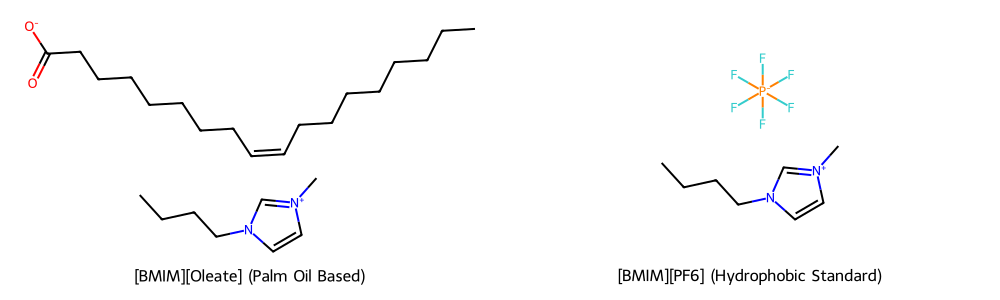

In [2]:
from rdkit import Chem
from rdkit.Chem import Draw
import io

# Define the SMILES strings
# We use 'r' before the string to ensure the backslash in the Oleate chain is read correctly
smiles_bmim_oleate = r'CCCCn1cc[n+](c1)C.CCCCCCCC/C=C\CCCCCCCC(=O)[O-]'
smiles_bmim_pf6 = r'CCCCn1cc[n+](c1)C.F[P-](F)(F)(F)(F)F'

# Create Molecule objects
mol_oleate = Chem.MolFromSmiles(smiles_bmim_oleate)
mol_pf6 = Chem.MolFromSmiles(smiles_bmim_pf6)

# Create a list to draw
mols = [mol_oleate, mol_pf6]
legends = ['[BMIM][Oleate] (Palm Oil Based)', '[BMIM][PF6] (Hydrophobic Standard)']

# --- FIX: Get raw PNG data instead of an Image object ---
img_data = Draw.MolsToGridImage(
    mols, 
    molsPerRow=2, 
    subImgSize=(500, 300), 
    legends=legends,
    useSVG=False,
    returnPNG=True  # This forces RDKit to return raw binary data
)

# Save the binary data to a file manually
output_path = '../data/indonesia_ionic_liquids_2D.png'

# If img_data is not bytes (older RDKit versions might still return a PIL image), 
# we handle both cases:
if hasattr(img_data, 'save'):
    # If it's a PIL image (standard behavior)
    img_data.save(output_path)
elif hasattr(img_data, 'data'):
    # If it's an IPython display object
    with open(output_path, 'wb') as f:
        f.write(img_data.data)
else:
    # If it's raw bytes (from returnPNG=True)
    with open(output_path, 'wb') as f:
        f.write(img_data)

print(f"Success! 2D structures saved to '{output_path}'")

# Display the image in the notebook
from IPython.display import Image
display(Image(filename=output_path))

In [3]:
import pandas as pd
import os
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem

# --- Configuration ---
# Path to your specific file
DATASET_PATH = '../data/ions_with_smiles.csv' 
OUTPUT_DIR = '../data/2d_structures'

# Create output folder if it doesn't exist
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)
    print(f"Created directory: {OUTPUT_DIR}")

# --- 1. Load Data ---
try:
    # Read the file
    df = pd.read_csv(DATASET_PATH)
    print(f"Loaded dataset with {len(df)} rows.")
    
    # Check if columns exist (case insensitive check)
    cols = [c.lower() for c in df.columns]
    required = ['ion_abbreviation', 'ion_name', 'ion_type', 'smiles']
    
    if not all(r in cols for r in required):
        print(f"Warning: Columns might not match exactly. Found: {df.columns.tolist()}")
        # Normalize column names for easier access
        df.columns = df.columns.str.lower()
    
except FileNotFoundError:
    print(f"Error: File not found at {DATASET_PATH}")
    df = pd.DataFrame()

if not df.empty:
    # --- 2. Separate Cations and Anions ---
    # Filter by 'ion_type' column (assuming values like 'cation'/'anion')
    cations = df[df['ion_type'].str.lower().str.contains('cation')]
    anions = df[df['ion_type'].str.lower().str.contains('anion')]
    
    print(f"Found {len(cations)} cations and {len(anions)} anions.")

    # --- 3. Function to Generate Images ---
    def generate_images(sub_df, type_label):
        valid_mols = []
        valid_legends = []
        
        print(f"\nProcessing {type_label}s...")
        
        for index, row in sub_df.iterrows():
            name = row['ion_abbreviation']
            full_name = row['ion_name']
            smiles = row['smiles']
            
            # Create filename: Type_Abbreviation.png
            # Remove illegal characters for filenames
            safe_name = str(name).replace('[','').replace(']','').replace('/','_').replace('\\','_')
            filename = f"{OUTPUT_DIR}/{type_label}_{safe_name}.png"
            
            try:
                mol = Chem.MolFromSmiles(smiles)
                if mol:
                    # Compute 2D coordinates
                    AllChem.Compute2DCoords(mol)
                    
                    # Save individual image
                    Draw.MolToFile(mol, filename, size=(300, 300))
                    
                    # Store for the grid
                    valid_mols.append(mol)
                    valid_legends.append(str(name)) # Use abbreviation for the grid legend
                else:
                    print(f"  Warning: Invalid SMILES for {name}")
            except Exception as e:
                print(f"  Error on {name}: {e}")
                
        return valid_mols, valid_legends

    # Generate for Cations
    cat_mols, cat_legends = generate_images(cations, "Cation")
    
    # Generate for Anions
    an_mols, an_legends = generate_images(anions, "Anion")
    
    print(f"\nSuccess! Individual images saved to '{OUTPUT_DIR}'")

    # --- 4. Generate Appendix Grids ---
    print("Generating Summary Grids for Appendix...")

    # Grid for Cations
    if cat_mols:
        img_grid_cat = Draw.MolsToGridImage(
            cat_mols, 
            molsPerRow=5, 
            subImgSize=(200, 200), 
            legends=cat_legends,
            returnPNG=False
        )
        img_grid_cat.save(f"{OUTPUT_DIR}/APPENDIX_Cations_Grid.png")
        print(f"Saved 'APPENDIX_Cations_Grid.png' ({len(cat_mols)} structures)")

    # Grid for Anions
    if an_mols:
        img_grid_an = Draw.MolsToGridImage(
            an_mols, 
            molsPerRow=5, 
            subImgSize=(200, 200), 
            legends=an_legends,
            returnPNG=False
        )
        img_grid_an.save(f"{OUTPUT_DIR}/APPENDIX_Anions_Grid.png")
        print(f"Saved 'APPENDIX_Anions_Grid.png' ({len(an_mols)} structures)")

Loaded dataset with 84 rows.
Found 56 cations and 28 anions.

Processing Cations...

Processing Anions...

Success! Individual images saved to '../data/2d_structures'
Generating Summary Grids for Appendix...
Saved 'APPENDIX_Cations_Grid.png' (56 structures)
Saved 'APPENDIX_Anions_Grid.png' (28 structures)


/Users/ragilzakaria/.pyenv/versions/3.11.1/lib/python3.11/site-packages/rdkit/Chem/Draw/IPythonConsole.py:343: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


In [4]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem

# --- Configuration ---
# Your DFT Method (Must match your thesis methodology)
ORCA_HEADER = "! r2SCAN-3c Opt Freq" 
CHARGE = -1  # Anions are usually -1
MULTIPLICITY = 1 # Singlet

# The Candidates to Calculation
candidates = {
    'Oleate': 'CCCCCCCC/C=C\CCCCCCCC(=O)[O-]',
    'Laurate': 'CCCCCCCCCCCC(=O)[O-]'
}

# Create folder
output_dir = '../orca_calculations'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

print(f"Generating ORCA inputs in '{output_dir}'...\n")

for name, smiles in candidates.items():
    # 1. Generate 3D Structure with RDKit
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol) # Crucial for DFT!
    
    # Embed 3D coords and optimize with MMFF (Force Field) first
    AllChem.EmbedMolecule(mol, AllChem.ETKDG())
    AllChem.MMFFOptimizeMolecule(mol)
    
    # 2. Convert to XYZ String
    xyz_block = ""
    for atom in mol.GetAtoms():
        pos = mol.GetConformer().GetAtomPosition(atom.GetIdx())
        xyz_block += f"{atom.GetSymbol()} {pos.x:.6f} {pos.y:.6f} {pos.z:.6f}\n"

    # 3. Write the .inp File
    filename = os.path.join(output_dir, f"{name}.inp")
    
    with open(filename, 'w') as f:
        f.write(f"# Input for {name}\n")
        f.write(f"{ORCA_HEADER}\n\n")
        f.write(f"* xyz {CHARGE} {MULTIPLICITY}\n")
        f.write(xyz_block)
        f.write("*\n")
    
    print(f"-> Created: {name}.inp")

print("\nDONE! Now run these files using your ORCA command (e.g., 'orca Oleate.inp > Oleate.out')")

Generating ORCA inputs in '../orca_calculations'...

-> Created: Oleate.inp
-> Created: Laurate.inp

DONE! Now run these files using your ORCA command (e.g., 'orca Oleate.inp > Oleate.out')
